# ¡Llena ese carrito!

# Introducción

Instacart es una plataforma de entregas de comestibles donde la clientela puede registrar un pedido y hacer que se lo entreguen, similar a Uber Eats y Door Dash.
El conjunto de datos que te hemos proporcionado tiene modificaciones del original. Redujimos el tamaño del conjunto para que tus cálculos se hicieran más rápido e introdujimos valores ausentes y duplicados. Tuvimos cuidado de conservar las distribuciones de los datos originales cuando hicimos los cambios.

Debes completar tres pasos. Para cada uno de ellos, escribe una breve introducción que refleje con claridad cómo pretendes resolver cada paso, y escribe párrafos explicatorios que justifiquen tus decisiones al tiempo que avanzas en tu solución.  También escribe una conclusión que resuma tus hallazgos y elecciones.


## Diccionario de datos

Hay cinco tablas en el conjunto de datos, y tendrás que usarlas todas para hacer el preprocesamiento de datos y el análisis exploratorio de datos. A continuación se muestra un diccionario de datos que enumera las columnas de cada tabla y describe los datos que contienen.

- `instacart_orders.csv`: cada fila corresponde a un pedido en la aplicación Instacart.
    - `'order_id'`: número de ID que identifica de manera única cada pedido.
    - `'user_id'`: número de ID que identifica de manera única la cuenta de cada cliente.
    - `'order_number'`: el número de veces que este cliente ha hecho un pedido.
    - `'order_dow'`: día de la semana en que se hizo el pedido (0 si es domingo).
    - `'order_hour_of_day'`: hora del día en que se hizo el pedido.
    - `'days_since_prior_order'`: número de días transcurridos desde que este cliente hizo su pedido anterior.
- `products.csv`: cada fila corresponde a un producto único que pueden comprar los clientes.
    - `'product_id'`: número ID que identifica de manera única cada producto.
    - `'product_name'`: nombre del producto.
    - `'aisle_id'`: número ID que identifica de manera única cada categoría de pasillo de víveres.
    - `'department_id'`: número ID que identifica de manera única cada departamento de víveres.
- `order_products.csv`: cada fila corresponde a un artículo pedido en un pedido.
    - `'order_id'`: número de ID que identifica de manera única cada pedido.
    - `'product_id'`: número ID que identifica de manera única cada producto.
    - `'add_to_cart_order'`: el orden secuencial en el que se añadió cada artículo en el carrito.
    - `'reordered'`: 0 si el cliente nunca ha pedido este producto antes, 1 si lo ha pedido.
- `aisles.csv`
    - `'aisle_id'`: número ID que identifica de manera única cada categoría de pasillo de víveres.
    - `'aisle'`: nombre del pasillo.
- `departments.csv`
    - `'department_id'`: número ID que identifica de manera única cada departamento de víveres.
    - `'department'`: nombre del departamento.

# Paso 1. Descripción de los datos

Lee los archivos de datos (`/datasets/instacart_orders.csv`, `/datasets/products.csv`, `/datasets/aisles.csv`, `/datasets/departments.csv` y `/datasets/order_products.csv`) con `pd.read_csv()` usando los parámetros adecuados para leer los datos correctamente. Verifica la información para cada DataFrame creado.


## Plan de solución

En esta etapa cargamos los conjuntos de datos y exploramos su contenido. Vemos las primeras filas, el tamaño de las tablas, los nombres de las columnas, los tipos de datos y la cantidad de valores no nulos. Esto permite identificar problemas con los datos para poder procesarlos correctamente

In [1]:
import pandas as pd
from matplotlib import pyplot as plt # importar librerías
from pathlib import Path

In [2]:
def data_path(filename): # leer conjuntos de datos en los DataFrames
    candidates = [
        Path('/datasets') / filename,
        Path('/content') / filename,
        Path('/mnt/data') / filename,
        Path(filename)
    ]
    for path in candidates:
        if path.exists():
            return path
    raise FileNotFoundError(
        f'No se encontró {filename}. En Colab, sube los cinco CSV a /content.'
    )

orders = pd.read_csv(data_path('instacart_orders.csv'), sep=';')
products = pd.read_csv(data_path('products.csv'), sep=';')
aisles = pd.read_csv(data_path('aisles.csv'), sep=';')
departments = pd.read_csv(data_path('departments.csv'), sep=';')
order_products = pd.read_csv(data_path('order_products.csv'), sep=';')

In [3]:
print(orders.head()) # mostrar información del DataFrame orders
print()
orders.info()

   order_id  user_id  ...  order_hour_of_day  days_since_prior_order
0   1515936   183418  ...                 13                    30.0
1   1690866   163593  ...                 12                     9.0
2   1454967    39980  ...                 19                     2.0
3   1768857    82516  ...                 20                    10.0
4   3007858   196724  ...                 12                    17.0

[5 rows x 6 columns]

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 478967 entries, 0 to 478966
Data columns (total 6 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   order_id                478967 non-null  int64  
 1   user_id                 478967 non-null  int64  
 2   order_number            478967 non-null  int64  
 3   order_dow               478967 non-null  int64  
 4   order_hour_of_day       478967 non-null  int64  
 5   days_since_prior_order  450148 non-null  float64
dtypes: float64(1), i

In [4]:
print(products.head()) # mostrar información del DataFrame products
print()
products.info()

   product_id  ... department_id
0           1  ...            19
1           2  ...            13
2           3  ...             7
3           4  ...             1
4           5  ...            13

[5 rows x 4 columns]

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 49694 entries, 0 to 49693
Data columns (total 4 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   product_id     49694 non-null  int64 
 1   product_name   48436 non-null  object
 2   aisle_id       49694 non-null  int64 
 3   department_id  49694 non-null  int64 
dtypes: int64(3), object(1)
memory usage: 1.5+ MB


In [5]:
print(aisles.head()) # mostrar información del DataFrame aisles
print()
aisles.info()

   aisle_id                       aisle
0         1       prepared soups salads
1         2           specialty cheeses
2         3         energy granola bars
3         4               instant foods
4         5  marinades meat preparation

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 134 entries, 0 to 133
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   aisle_id  134 non-null    int64 
 1   aisle     134 non-null    object
dtypes: int64(1), object(1)
memory usage: 2.2+ KB


In [6]:
print(departments.head()) # mostrar información del DataFrame departments
print()
departments.info()

   department_id department
0              1     frozen
1              2      other
2              3     bakery
3              4    produce
4              5    alcohol

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 2 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   department_id  21 non-null     int64 
 1   department     21 non-null     object
dtypes: int64(1), object(1)
memory usage: 468.0+ bytes


In [7]:
print(order_products.head()) # mostrar información del DataFrame order_products
print()
order_products.info(show_counts=True)

   order_id  product_id  add_to_cart_order  reordered
0   2141543       11440               17.0          0
1    567889        1560                1.0          1
2   2261212       26683                1.0          1
3    491251        8670               35.0          1
4   2571142        1940                5.0          1

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4545007 entries, 0 to 4545006
Data columns (total 4 columns):
 #   Column             Non-Null Count    Dtype  
---  ------             --------------    -----  
 0   order_id           4545007 non-null  int64  
 1   product_id         4545007 non-null  int64  
 2   add_to_cart_order  4544171 non-null  float64
 3   reordered          4545007 non-null  int64  
dtypes: float64(1), int64(3)
memory usage: 138.7 MB


## Conclusiones



- Los 5 ".csv" se cargaron correctamente, no usamos el separador "," en su lugar usamos el separador ";".
- En nuestro dataset tenemos los archivos: orders, con 478967 filas; products, con 49694; aisles, con 134; departments, con 21; y order_products, con 4545007 filas. Los identificadores y las variables discretas se almacenan como valores de tipo entero.
- Tenemos valores ausentes en: days_since_prior_order, con 28819 valores ausentes; product_name, con 1258 valores ausentes; y add_to_cart_order, con 836 valores ausentes.
- Debemos comprobar los registros duplicados para plantear un tratamiento correcto para cada problema.




# Paso 2. Preprocesamiento de los datos

Preprocesa los datos de la siguiente manera:

- Verifica y corrige los tipos de datos (por ejemplo, asegúrate de que las columnas de ID sean números enteros).
- Identifica y completa los valores ausentes.
- Identifica y elimina los valores duplicados.

Asegúrate de explicar qué tipos de valores ausentes y duplicados encontraste, cómo los completaste o eliminaste y por qué usaste esos métodos. ¿Por qué crees que estos valores ausentes y duplicados pueden haber estado presentes en el conjunto de datos?

## Plan de solución

Primero revisamos los tipos de datos de cada DataFrame para verificar que las columnas identificadoras y las variables discretas tengan el tipo adecuado. También revisamos las filas completamente duplicadas y los posibles duplicados en las columnas que deberían contener identificadores únicos. Después analizamos los valores ausentes para determinar si corresponden a errores o si tienen una explicación lógica dentro del contexto de los datos. Finalmente, aplicamos las correcciones necesarias y verificamos que los DataFrames queden preparados para el análisis exploratorio.

### Revisión de tipos de datos

Comprobamos los tipos de datos de las cinco tablas antes de hacer cambios. Prestamos especial atención a las columnas identificadoras para confirmar que sean enteros. Las columnas `days_since_prior_order` y `add_to_cart_order` pueden aparecer inicialmente como `float` por la presencia de valores ausentes. La primera se conserva con sus valores `NaN`, porque representan el primer pedido; la segunda se convierte a entero después de completar sus ausentes.

In [8]:
# Verificamos los tipos de datos en las cinco tablas.
datasets = {
    'orders': orders,
    'products': products,
    'aisles': aisles,
    'departments': departments,
    'order_products': order_products
}

id_columns = {
    'orders': ['order_id', 'user_id'],
    'products': ['product_id', 'aisle_id', 'department_id'],
    'aisles': ['aisle_id'],
    'departments': ['department_id'],
    'order_products': ['order_id', 'product_id']
}

for name, dataframe in datasets.items():
    print(f'\n{name}:')
    print(dataframe.dtypes)
    for column in id_columns[name]:
        assert pd.api.types.is_integer_dtype(dataframe[column]), (
            f'La columna {name}.{column} no es de tipo entero'
        )

print('\nVerificación completa: todas las columnas de ID tienen tipo entero.')



orders:
order_id                    int64
user_id                     int64
order_number                int64
order_dow                   int64
order_hour_of_day           int64
days_since_prior_order    float64
dtype: object

products:
product_id        int64
product_name     object
aisle_id          int64
department_id     int64
dtype: object

aisles:
aisle_id     int64
aisle       object
dtype: object

departments:
department_id     int64
department       object
dtype: object

order_products:
order_id               int64
product_id             int64
add_to_cart_order    float64
reordered              int64
dtype: object

Verificación completa: todas las columnas de ID tienen tipo entero.


## Encuentra y elimina los valores duplicados (y describe cómo tomaste tus decisiones).

### `orders` data frame

In [9]:
# Revisa si hay pedidos duplicados
print('Filas duplicadas:', orders.duplicated().sum())
duplicated_orders = orders[orders.duplicated(keep=False)].sort_values('order_id')
duplicated_orders

Filas duplicadas: 15


,order_id,user_id,order_number,order_dow,order_hour_of_day,days_since_prior_order
354993,391768,57671,19,3,2,10.0
371905,391768,57671,19,3,2,10.0
119251,408114,68324,4,3,2,18.0
321100,408114,68324,4,3,2,18.0
394347,467134,63189,21,3,2,2.0
250626,467134,63189,21,3,2,2.0
145574,794638,50898,24,3,2,2.0
99462,794638,50898,24,3,2,2.0
242618,1021560,53767,3,3,2,9.0
311713,1021560,53767,3,3,2,9.0


¿Tienes líneas duplicadas? Si sí, ¿qué tienen en común?

Sí. Hay 15 filas duplicadas adicionales, estas corresponden a 15 pedidos repetidos. 
Al revisar los registros duplicados, observamos que todos fueron realizados el miércoles (order_dow = 3) a las 2:00 a. m. (order_hour_of_day = 2).

In [10]:
# Basándote en tus hallazgos, verifica todos los pedidos que se hicieron el miércoles a las 2:00 a.m.
wednesday_2am = orders[(orders['order_dow'] == 3) & (orders['order_hour_of_day'] == 2)]
print('Filas encontradas:', len(wednesday_2am))
print('order_id únicos:', wednesday_2am['order_id'].nunique())
wednesday_2am.head(10)

Filas encontradas: 121
order_id únicos: 106


,order_id,user_id,order_number,order_dow,order_hour_of_day,days_since_prior_order
4838,2766110,162084,41,3,2,16.0
5156,2190225,138285,18,3,2,11.0
15506,553049,58599,13,3,2,7.0
18420,382357,120200,19,3,2,11.0
24691,690242,77357,2,3,2,9.0
25376,1378085,75705,21,3,2,5.0
26301,2846262,176827,2,3,2,30.0
29129,353088,46038,4,3,2,11.0
30371,1918001,188546,14,3,2,16.0
31404,1725788,147843,10,3,2,30.0


¿Qué sugiere este resultado?

Sugiere que hay 121 registros realizados el miércoles a las 2:00 a. m., pero solo 106 order_id distintos.
La diferencia es exactamente de 15 registros, así que los duplicados están en este grupo, no todos los pedidos de ese horario están repetidos; se trata de un error específico del registro

In [11]:
orders = orders.drop_duplicates().reset_index(drop=True) # Elimina los pedidos duplicados

In [12]:
print('Filas duplicadas:', orders.duplicated().sum()) # Vuelve a verificar si hay filas duplicadas


Filas duplicadas: 0


In [13]:
print('order_id duplicados:', orders['order_id'].duplicated().sum()) # Vuelve a verificar únicamente si hay IDs duplicados de pedidos

order_id duplicados: 0


Describe brevemente tus hallazgos y lo que hiciste con ellos:

Eliminamos las 15 filas duplicadas con drop_duplicates(), luego de la limpieza ya no quedan filas duplicadas ni valores repetidos de order_id.

### `products` data frame

In [14]:
print('Filas totalmente duplicadas:', products.duplicated().sum()) # Verifica si hay filas totalmente duplicadas

Filas totalmente duplicadas: 0


In [15]:
print('product_id duplicados:', products['product_id'].duplicated().sum()) # Revisa únicamente si hay ID de productos duplicados

product_id duplicados: 0


In [16]:
product_names_upper = products['product_name'].str.upper() # Revisa únicamente si hay nombres duplicados de productos (convierte los nombres a letras mayúsculas para compararlos mejor)
print('Nombres duplicados, incluyendo valores ausentes:', product_names_upper.duplicated().sum()) 

Nombres duplicados, incluyendo valores ausentes: 1361


In [17]:
non_null_name_duplicates = products[  #Revisa si hay nombres duplicados de productos no faltantes
    products['product_name'].notna()
    & product_names_upper.duplicated(keep=False)
].sort_values('product_name')

print('Filas con nombres duplicados no ausentes:', len(non_null_name_duplicates))
print('Nombres duplicados distintos:', non_null_name_duplicates['product_name'].str.upper().nunique())
non_null_name_duplicates.head(20)


Filas con nombres duplicados no ausentes: 207
Nombres duplicados distintos: 103


,product_id,product_name,aisle_id,department_id
31844,31845,18-In-1 Hemp Peppermint Pure-Castile Soap,25,11
23339,23340,18-in-1 Hemp Peppermint Pure-Castile Soap,25,11
19941,19942,Aged Balsamic Vinegar Of Modena,19,13
13152,13153,Aged Balsamic Vinegar of Modena,19,13
22582,22583,Albacore Solid White Tuna In Water,95,15
24830,24831,Albacore Solid White Tuna in Water,95,15
515,516,American Cheese Slices,21,16
9037,9038,American Cheese slices,21,16
49530,49531,Anchovy Fillets In Olive Oil,95,15
12325,12326,Anchovy Fillets in Olive Oil,95,15


Describe brevemente tus hallazgos y lo que hiciste con ellos:

- No hay filas totalmente duplicadas ni product_id repetidos. 
- Existen nombres de productos repetidos al ignorar diferencias entre mayúsculas y minúsculas, pero pertenecen a identificadores de producto diferentes, Por eso no se eliminaron.
- El identificador es crítico, porque distingue a cada producto.
- Se detectaron valores ausentes en product_name

### `departments` data frame

In [18]:
print('Filas totalmente duplicadas:', departments.duplicated().sum()) # Revisa si hay filas totalmente duplicadas

Filas totalmente duplicadas: 0


In [19]:
print('department_id duplicados:', departments['department_id'].duplicated().sum()) # Revisa únicamente si hay IDs duplicadas de departamentos

department_id duplicados: 0


Describe brevemente tus hallazgos y lo que hiciste con ellos.

No fué necesario modificar este dataframe, porque no hay filas duplicadas ni identificadores de departamento repetidos.

### `aisles` data frame

In [20]:
print('Filas totalmente duplicadas:', aisles.duplicated().sum()) # Revisa si hay filas totalmente duplicadas

Filas totalmente duplicadas: 0


In [21]:
print('aisle_id duplicados:', aisles['aisle_id'].duplicated().sum()) # Revisa únicamente si hay IDs duplicadas de pasillos

aisle_id duplicados: 0


Describe brevemente tus hallazgos y lo que hiciste con ellos:

Igual que el anterior, no fué necesario modificar este dataframe porque no hay filas duplicadas ni identificadores de departamento repetidos.

### `order_products` data frame

In [22]:
print('Filas totalmente duplicadas:', order_products.duplicated().sum()) # Revisa si hay filas totalmente duplicadas

Filas totalmente duplicadas: 0


In [23]:
print(                                           # Vuelve a verificar si hay cualquier otro duplicado engañoso
    'Pares order_id-product_id duplicados:',
    order_products.duplicated(subset=['order_id', 'product_id']).sum()
)

Pares order_id-product_id duplicados: 0


Describe brevemente tus hallazgos y lo que hiciste con ellos.

Similar a lso dos anterores, no se encontraron filas totalmente duplicadas ni combinaciones repetidas de order_id y product_id. Así que no fué necesario modificar el dataframe.

## Encuentra y elimina los valores ausentes

Al trabajar con valores duplicados, pudimos observar que también nos falta investigar valores ausentes:

* La columna `'product_name'` de la tabla products.
* La columna `'days_since_prior_order'` de la tabla orders.
* La columna `'add_to_cart_order'` de la tabla order_productos.

### `products` data frame

In [24]:
print('Valores ausentes en product_name:', products['product_name'].isna().sum()) # Encuentra los valores ausentes en la columna 'product_name'
products[products['product_name'].isna()].head()

Valores ausentes en product_name: 1258


,product_id,product_name,aisle_id,department_id
37,38,NaN,100,21
71,72,NaN,100,21
109,110,NaN,100,21
296,297,NaN,100,21
416,417,NaN,100,21


Describe brevemente cuáles son tus hallazgos.

Hay 1258 valores ausentes en product_name. Como los demás campos de estas filas sí contienen información, investigamos si los productos ausentes comparten una categoría antes de reemplazar los nombres.

In [25]:
#  ¿Todos los nombres de productos ausentes están relacionados con el pasillo con ID 100?
missing_products = products[products['product_name'].isna()]
print((missing_products['aisle_id'] == 100).all())

True


Describe brevemente cuáles son tus hallazgos.

Sí, todos los productos cuyo nombre está ausente pertenecen al pasillo con ID 100.

In [26]:
# ¿Todos los nombres de productos ausentes están relacionados con el departamento con ID 21?
print((missing_products['department_id'] == 21).all())

True


Describe brevemente cuáles son tus hallazgos.

Sí, todos los productos con product_name ausente, también pertenecen al departamento con ID 21.

In [27]:
# Usa las tablas department y aisle para revisar los datos del pasillo con ID 100 y el departamento con ID 21.
print(aisles[aisles['aisle_id'] == 100])
print()
print(departments[departments['department_id'] == 21])

    aisle_id    aisle
99       100  missing

    department_id department
20             21    missing


Describe brevemente cuáles son tus hallazgos.

El pasillo 100 y el departamento 21 aparecen identificados como missing, lo que confirma que la ausencia del nombre forma parte de registros cuya clasificación tampoco se conoce.

In [28]:
products['product_name'] = products['product_name'].fillna('Unknown') # Completa los nombres de productos ausentes con 'Unknown'
print('Valores ausentes restantes:', products['product_name'].isna().sum())

Valores ausentes restantes: 0


Describe brevemente tus hallazgos y lo que hiciste con ellos.

Reemplazamos los 1258 nombres ausentes por Unknown. Así conservando cada product_id sin inventar un nombre de producto que no existe en los datos.

### `orders` data frame

In [29]:
print(orders.isna().sum()) # Encuentra los valores ausentes

order_id                      0
user_id                       0
order_number                  0
order_dow                     0
order_hour_of_day             0
days_since_prior_order    28817
dtype: int64


In [30]:
# ¿Hay algún valor ausente que no sea el primer pedido del cliente?
missing_days_not_first = orders[
    orders['days_since_prior_order'].isna()
    & (orders['order_number'] != 1)
]
print('Valores ausentes que no corresponden al primer pedido:', len(missing_days_not_first))

Valores ausentes que no corresponden al primer pedido: 0


No, no hay valores ausentes que no corresponden al primer pedido.

Describe brevemente tus hallazgos y lo que hiciste con ellos.

Los 28819 valores ausentes de days_since_prior_order corresponden exclusivamente al primer pedido de cada cliente, esto es lógico porque un primer pedido no tiene un pedido anterior con el cual calcular una diferencia de días. Por ello se conservaron como NaN en vez de asignarles un valor artificial.

### `order_products` data frame

In [31]:
print(order_products.isna().sum()) # Encuentra los valores ausentes

order_id               0
product_id             0
add_to_cart_order    836
reordered              0
dtype: int64


In [32]:
# ¿Cuáles son los valores mínimos y máximos en esta columna?
print('Mínimo:', order_products['add_to_cart_order'].min())
print('Máximo:', order_products['add_to_cart_order'].max())

Mínimo: 1.0
Máximo: 64.0


Describe brevemente cuáles son tus hallazgos.

La columna add_to_cart_order contiene 836 valores ausentes. 
Entre los valores registrados, la posición mínima es 1 y la máxima es 64, por lo que es necesario comprobar si los datos ausentes aparecen en pedidos que superan ese tamaño.

In [33]:
missing_order_ids = order_products.loc[    # Guarda todas las IDs de pedidos que tengan un valor ausente en 'add_to_cart_order'
    order_products['add_to_cart_order'].isna(),
    'order_id'
].unique()

print('Pedidos con valores ausentes:', len(missing_order_ids))

Pedidos con valores ausentes: 70


In [34]:
# ¿Todos los pedidos con valores ausentes tienen más de 64 productos?
# Agrupa todos los pedidos con datos ausentes por su ID de pedido.
# Cuenta el número de 'product_id' en cada pedido y revisa el valor mínimo del conteo.
missing_orders_sizes = (
    order_products[order_products['order_id'].isin(missing_order_ids)]
    .groupby('order_id')['product_id']
    .count()
)

print('Tamaño mínimo de esos pedidos:', missing_orders_sizes.min())
print('Tamaño máximo de esos pedidos:', missing_orders_sizes.max())
print('¿Todos tienen más de 64 productos?', (missing_orders_sizes > 64).all())

Tamaño mínimo de esos pedidos: 65
Tamaño máximo de esos pedidos: 127
¿Todos tienen más de 64 productos? True


Describe brevemente cuáles son tus hallazgos.

Los 836 valores ausentes de add_to_cart_order pertenecen a 70 pedidos. 
Todos esos pedidos contienen más de 64 productos: el menor tiene 65 y el mayor 127, esto podría sugerir que el sistema dejó de registrar la posición a partir de cierto límite, en lugar de que los valores falten de manera aleatoria.

In [35]:
# Remplaza los valores ausentes en la columna 'add_to_cart? con 999 y convierte la columna al tipo entero.
order_products['add_to_cart_order'] = (
    order_products['add_to_cart_order']
    .fillna(999)
    .astype(int)
)

print(order_products['add_to_cart_order'].dtype)
print('Valores ausentes restantes:', order_products['add_to_cart_order'].isna().sum())

int64


Valores ausentes restantes: 0


Describe brevemente tus hallazgos y lo que hiciste con ellos.

Reemplazamos los valores ausentes de add_to_cart_order por 999. 
Este valor funciona como marcador porque está muy por encima de la posición máxima válida observada (64) y evita confundir un dato desconocido con una posición real, después se convirtió la columna a entero.

## Conclusiones

- El procesamiento previo de los datos, permitió eliminar 15 pedidos duplicados y sin perder pedidos únicos
- No se detectaron duplicados problemáticos en las demás tablas. 
- Los nombres ausentes de productos se reemplazaron por Unknown porque pertenecían al pasillo y departamento marcados como missing.
- Los valores ausentes de days_since_prior_order se conservaron porque representan de forma lógica el primer pedido de cada cliente.
- En add_to_cart_order, los valores faltantes aparecen exclusivamente en pedidos con más de 64 productos; se reemplazaron por 999 y la columna se convirtió a entero.
- Después de estas correcciones, los datos están listos para el análisis exploratorio.
- Verificamos explícitamente los tipos de datos de las cinco tablas. Todas las columnas identificadoras ya tienen tipo entero. Conservamos `days_since_prior_order` como numérica con ausentes válidos y convertimos `add_to_cart_order` a entero después de completar sus ausentes.


# Paso 3. Análisis de los datos

Una vez los datos estén procesados y listos, haz el siguiente análisis:

# [A] Fácil (deben completarse todos para aprobar)

1. Verifica que los valores en las columnas `'order_hour_of_day'` y `'order_dow'` en la tabla orders sean razonables (es decir, `'order_hour_of_day'` oscile entre 0 y 23 y `'order_dow'` oscile entre 0 y 6).
2. Crea un gráfico que muestre el número de personas que hacen pedidos dependiendo de la hora del día.
3. Crea un gráfico que muestre qué día de la semana la gente hace sus compras.
4. Crea un gráfico que muestre el tiempo que la gente espera hasta hacer su siguiente pedido, y comenta sobre los valores mínimos y máximos.

### [A1] Verifica que los valores sean sensibles

In [36]:
print('Hora mínima:', orders['order_hour_of_day'].min()) # Rango de horas del día
print('Hora máxima:', orders['order_hour_of_day'].max())
print('Valores:', sorted(orders['order_hour_of_day'].unique()))

Hora mínima: 0
Hora máxima: 23
Valores: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18), np.int64(19), np.int64(20), np.int64(21), np.int64(22), np.int64(23)]


In [37]:
print('Día mínimo:', orders['order_dow'].min()) # Rango de días de la semana
print('Día máximo:', orders['order_dow'].max())
print('Valores:', sorted(orders['order_dow'].unique()))

Día mínimo: 0
Día máximo: 6


Valores: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6)]


Los valores son correctos, order_hour_of_day contiene únicamente horas de 0 a 23 y order_dow únicamente días de 0 a 6
No hay valores fuera de los rangos esperados.

### [A2] Para cada hora del día, ¿cuántas personas hacen órdenes?

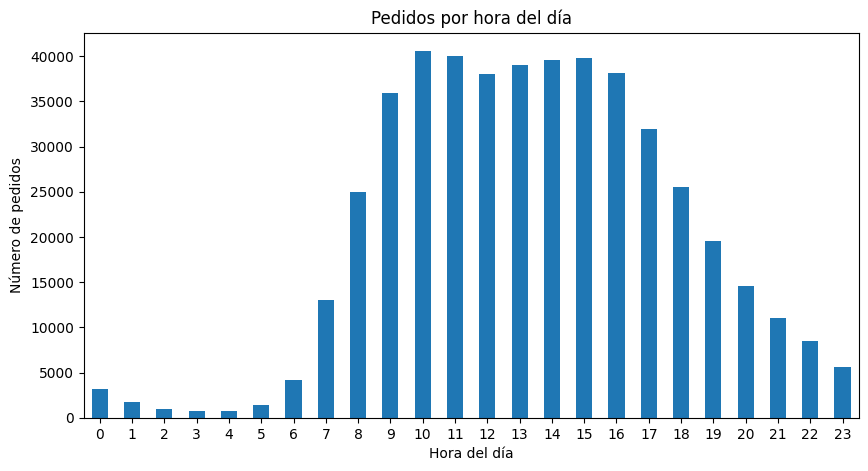

In [38]:
orders_by_hour = orders['order_hour_of_day'].value_counts().sort_index()
orders_by_hour.plot(
    kind='bar',
    figsize=(10, 5),
    title='Pedidos por hora del día',
    xlabel='Hora del día',
    ylabel='Número de pedidos',
    legend=False
)
plt.xticks(rotation=0)
plt.show()

La actividad es muy baja durante la madrugada y aumenta con rapidez desde las 7. 
La mayor cantidad de pedidos se registran alrededor de las 10, con 40578 pedidos.
Entre las 10 y las 16 se mantiene un nivel alto, y después disminuye progresivamente durante la tarde y la noche.

### [A3] ¿Qué día de la semana compran víveres las personas?

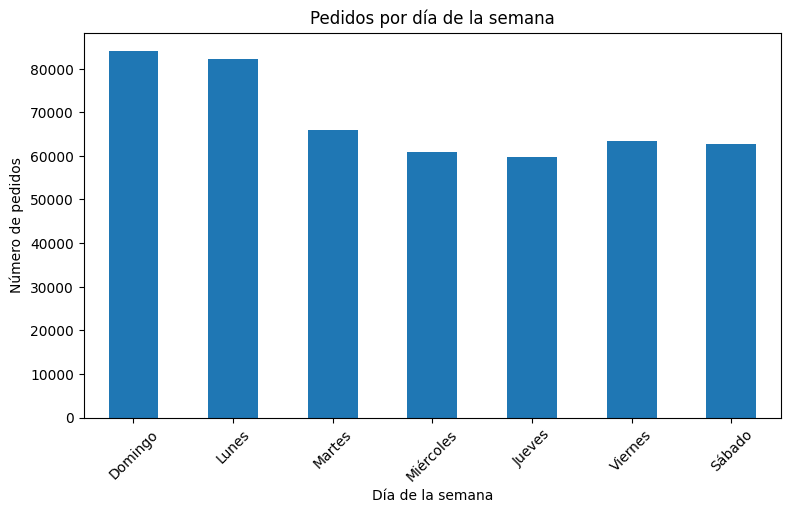

In [39]:
orders_by_day = orders['order_dow'].value_counts().sort_index()
day_names = ['Domingo', 'Lunes', 'Martes', 'Miércoles', 'Jueves', 'Viernes', 'Sábado']

orders_by_day.plot(
    kind='bar',
    figsize=(9, 5),
    title='Pedidos por día de la semana',
    xlabel='Día de la semana',
    ylabel='Número de pedidos',
    legend=False
)
plt.xticks(range(7), day_names, rotation=45)
plt.show()

El domingo es el día con más pedidos, con 84090, seguido del lunes.
El jueves presenta la menor cantidad, con 59810 pedidos. 
En general, la actividad es más alta al inicio de la semana y más baja entre martes y sábado.

### [A4] ¿Cuánto tiempo esperan las personas hasta hacer otro pedido? Comenta sobre los valores mínimos y máximos.

Mínimo: 0.0
Máximo: 30.0


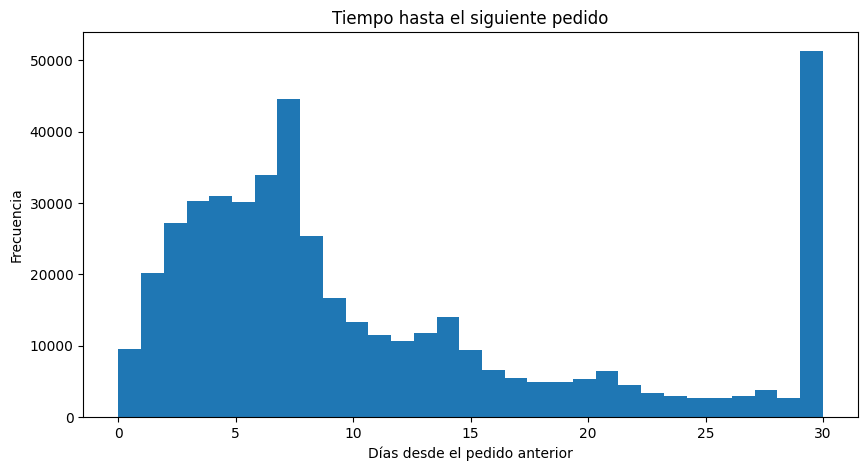

In [40]:
print('Mínimo:', orders['days_since_prior_order'].min())
print('Máximo:', orders['days_since_prior_order'].max())

orders['days_since_prior_order'].plot(
    kind='hist',
    bins=31,
    figsize=(10, 5),
    title='Tiempo hasta el siguiente pedido',
    xlabel='Días desde el pedido anterior'
)
plt.ylabel('Frecuencia')
plt.show()


El tiempo entre pedidos varía de 0 a 30 días.
Se observa un pico importante alrededor de 7 días, lo que sugiere un patrón semanal, y otro muy alto en 30 días. 
El valor 30 probablemente concentra intervalos de un mes o más debido al límite utilizado en el conjunto de datos.

# [B] Intermedio (deben completarse todos para aprobar)

1. ¿Existe alguna diferencia entre las distribuciones de `order_hour_of_day` de los miércoles y los sábados? Trazamos los histogramas de ambos días en la misma figura y describimos sus diferencias.
2. Graficamos la distribución del número de pedidos que hacen los clientes.
3. Identificamos los 20 productos más pedidos, con su ID y su nombre.


### [B1] Comparación de la distribución horaria de pedidos entre miércoles y sábado mediante histogramas.


In [41]:
wednesday_orders = orders[orders['order_dow'] == 3] # Pedidos del miércoles (3) y sábado (6)
saturday_orders = orders[orders['order_dow'] == 6]

In [42]:
wednesday_hours = wednesday_orders['order_hour_of_day'].value_counts().sort_index()
saturday_hours = saturday_orders['order_hour_of_day'].value_counts().sort_index()

hour_comparison = pd.DataFrame({
    'Miércoles': wednesday_hours,
    'Sábado': saturday_hours
}).fillna(0)

hour_comparison.head()

,Miércoles,Sábado
order_hour_of_day,,
0,373,464
1,215,254
2,106,177
3,101,125
4,108,118


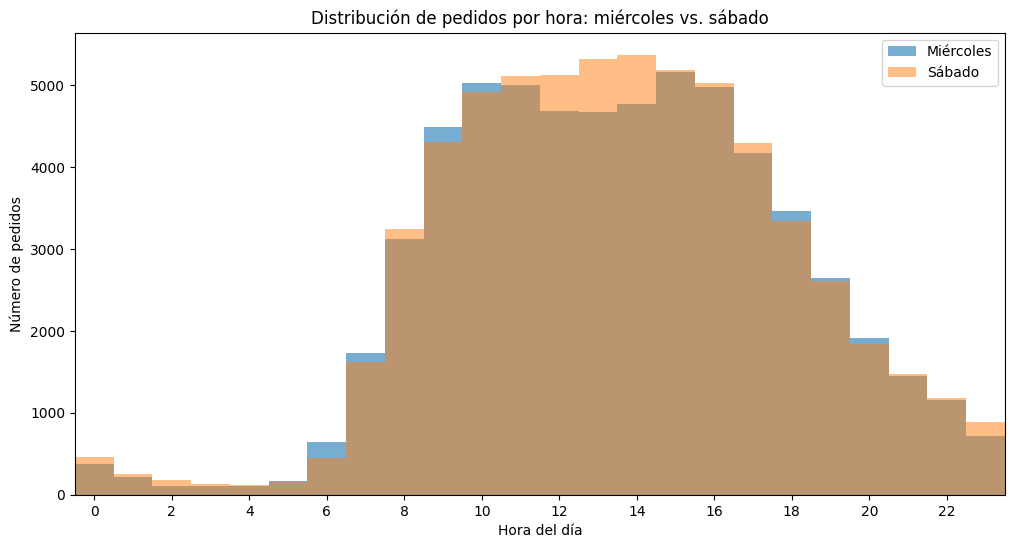

In [43]:
# Mostramos los dos histogramas en una sola figura, con un intervalo por hora.
# Los límites centrados en cada hora permiten comparar valores de 0 a 23.
bins_horas = [hora - 0.5 for hora in range(25)]

plt.figure(figsize=(12, 6))
plt.hist(
    wednesday_orders['order_hour_of_day'],
    bins=bins_horas,
    alpha=0.6,
    label='Miércoles'
)
plt.hist(
    saturday_orders['order_hour_of_day'],
    bins=bins_horas,
    alpha=0.5,
    label='Sábado'
)
plt.title('Distribución de pedidos por hora: miércoles vs. sábado')
plt.xlabel('Hora del día')
plt.ylabel('Número de pedidos')
plt.xticks(range(0, 24, 2))
plt.xlim(-0.5, 23.5)
plt.legend()
plt.show()


In [44]:
print('Pico del miércoles:', wednesday_hours.idxmax(), '-', wednesday_hours.max(), 'pedidos')
print('Pico del sábado:', saturday_hours.idxmax(), '-', saturday_hours.max(), 'pedidos')

Pico del miércoles: 15 - 5163 pedidos
Pico del sábado: 14 - 5375 pedidos


Los pedidos de miércoles y sábado muestran una distribución similar: hay poca actividad de madrugada y la frecuencia aumenta durante el día. El miércoles registramos su mayor actividad a las 15:00 (5163 pedidos), mientras que el sábado el máximo se alcanza a las 14:00 (5375 pedidos). Observamos que ambos días presentan bastante movimiento entre la mañana y la tarde, aunque el sábado tiene un pico algo más temprano.


### [B2] ¿Cuál es la distribución para el número de pedidos por cliente?

In [45]:
# Identificamos el número de pedidos de cada cliente mediante su mayor order_number.
orders_per_user = orders.groupby('user_id')['order_number'].max()

# Contamos cuántos clientes presentan cada cantidad de pedidos.
order_count_distribution = orders_per_user.value_counts().sort_index()
print(order_count_distribution.head(15))
print()
print('Resumen del número de pedidos por cliente:')
print(orders_per_user.describe())


order_number
1      7840
2      9113
3     10510
4     12368
5     10406
6      9194
7      7901
8      6894
9      6118
10     5497
11     4903
12     4411
13     4105
14     3792
15     3402
Name: count, dtype: int64

Resumen del número de pedidos por cliente:
count    157437.000000
mean         15.577571
std          17.215517
min           1.000000
25%           4.000000
50%           9.000000
75%          20.000000
max         100.000000
Name: order_number, dtype: float64


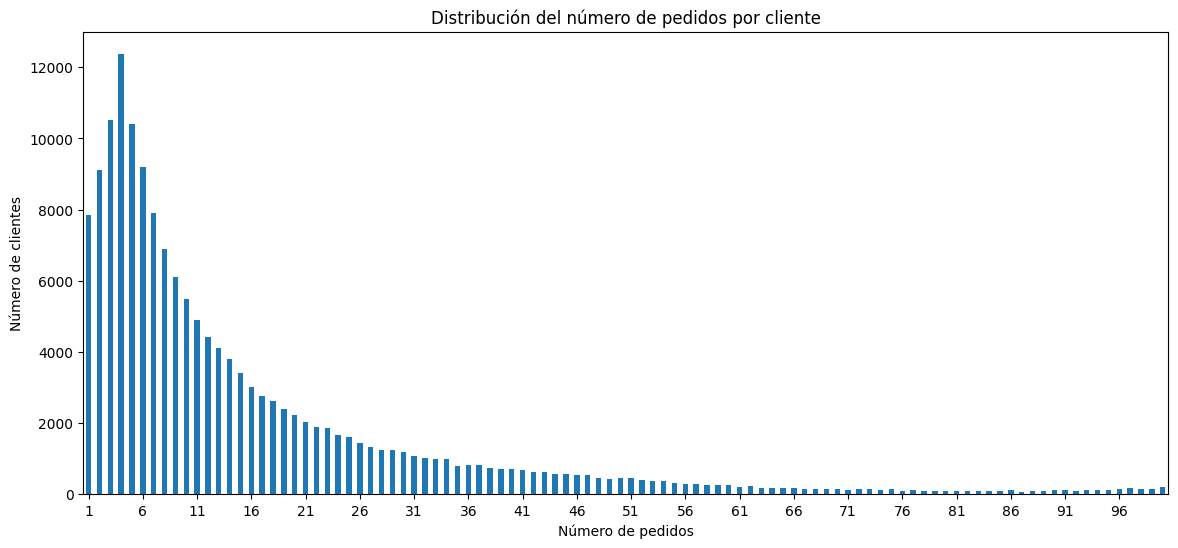

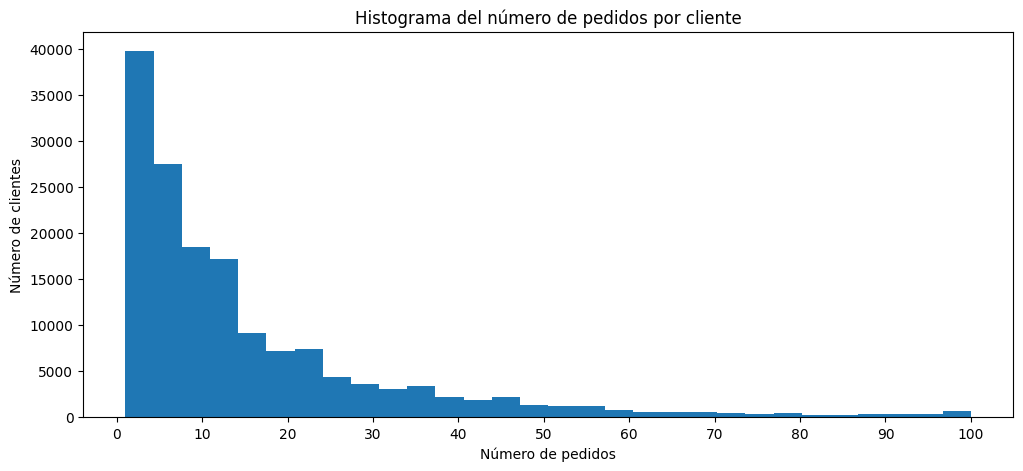

In [46]:
# Mostramos la distribución del número de pedidos por cliente.
order_count_distribution.plot(
    kind='bar',
    figsize=(14, 6),
    title='Distribución del número de pedidos por cliente',
    xlabel='Número de pedidos',
    ylabel='Número de clientes',
    legend=False
)
plt.xticks(
    ticks=range(0, len(order_count_distribution), 5),
    labels=order_count_distribution.index[::5],
    rotation=0
)
plt.show()

# Mostramos también el histograma de pedidos por cliente.
orders_per_user.plot(
    kind='hist',
    bins=30,
    figsize=(12, 5),
    title='Histograma del número de pedidos por cliente',
    xlabel='Número de pedidos'
)
plt.ylabel('Número de clientes')
plt.xticks(range(0, 101, 10))
plt.show()


La mayor cantidad de clientes se concentra en los números bajos de pedidos y disminuye a medida que el número de pedidos aumenta. Observamos que **4 pedidos** es la cantidad más frecuente (12,368 clientes), mientras que la mediana es **9 pedidos**. También hay clientes que alcanzan los 100 pedidos, pero son mucho menos comunes.

En este análisis utilizamos el mayor `order_number` de cada cliente, ya que indica el número acumulado de pedidos que ha realizado, no únicamente cuántas filas aparecen en esta muestra.


### [B3] ¿Cuáles son los 20 productos más populares (muestra su ID y nombre)?

In [47]:
# Contamos cuántas veces aparece cada producto entre los pedidos.
product_counts = order_products['product_id'].value_counts()
print(product_counts.head(20))


product_id
24852    66050
13176    53297
21137    37039
21903    33971
47209    29773
47766    24689
47626    21495
16797    20018
26209    19690
27845    19600
27966    19197
22935    15898
24964    15292
45007    14584
39275    13879
49683    13675
28204    12544
5876     12232
8277     11993
40706    11781
Name: count, dtype: int64


In [48]:
# Seleccionamos los 20 más frecuentes y agregamos sus nombres.
top20_products = (
    product_counts.head(20)
    .rename('order_count')
    .rename_axis('product_id')
    .reset_index()
    .merge(products[['product_id', 'product_name']], on='product_id', how='left')
)
top20_products = top20_products[['product_id', 'product_name', 'order_count']]


In [49]:
# Mostramos el ID, el nombre y el número de pedidos.
print(top20_products.to_string(index=False))


 product_id             product_name  order_count
      24852                   Banana        66050
      13176   Bag of Organic Bananas        53297
      21137     Organic Strawberries        37039
      21903     Organic Baby Spinach        33971
      47209     Organic Hass Avocado        29773
      47766          Organic Avocado        24689
      47626              Large Lemon        21495
      16797             Strawberries        20018
      26209                    Limes        19690
      27845       Organic Whole Milk        19600
      27966      Organic Raspberries        19197
      22935     Organic Yellow Onion        15898
      24964           Organic Garlic        15292
      45007         Organic Zucchini        14584
      39275      Organic Blueberries        13879
      49683           Cucumber Kirby        13675
      28204       Organic Fuji Apple        12544
       5876            Organic Lemon        12232
       8277 Apple Honeycrisp Organic        11993


Los productos más solicitados son principalmente frutas, verduras y otros productos frescos. Encontramos a **Banana** (ID 24852) en el primer lugar con **66,050** apariciones, seguida de **Bag of Organic Bananas** (ID 13176) con **53,297** y **Organic Strawberries** (ID 21137) con **37,039**.


# [C] Difícil (deben completarse todos para aprobar)

1. ¿Cuántos artículos suelen comprar las personas en un pedido? ¿Cómo es la distribución?
2. ¿Cuáles son los 20 principales artículos que vuelven a pedirse con mayor frecuencia (muestra sus nombres e IDs de los productos)?
3. Para cada producto, ¿cuál es la tasa de repetición del pedido (número de repeticiones de pedido/total de pedidos?
4. Para cada cliente, ¿qué proporción de los productos que pidió ya los había pedido? Calcula la tasa de repetición de pedido para cada usuario en lugar de para cada producto.
5. ¿Cuáles son los 20 principales artículos que la gente pone primero en sus carritos (muestra las IDs de los productos, sus nombres, y el número de veces en que fueron el primer artículo en añadirse al carrito)?

### [C1] ¿Cuántos artículos compran normalmente las personas en un pedido? ¿Cómo es la distribución?

In [50]:
# Contamos los productos de cada pedido.
items_per_order = order_products.groupby('order_id')['product_id'].count()
print(items_per_order.head())


order_id
4     13
9     15
11     5
19     3
20     8
Name: product_id, dtype: int64


In [51]:
# Revisamos los valores más comunes y las estadísticas principales.
print(items_per_order.describe())
print()
print('Moda:', items_per_order.mode().iloc[0])
print('Mediana:', items_per_order.median())


count    450046.000000
mean         10.098983
std           7.540206
min           1.000000
25%           5.000000
50%           8.000000
75%          14.000000
max         127.000000
Name: product_id, dtype: float64

Moda: 5
Mediana: 8.0


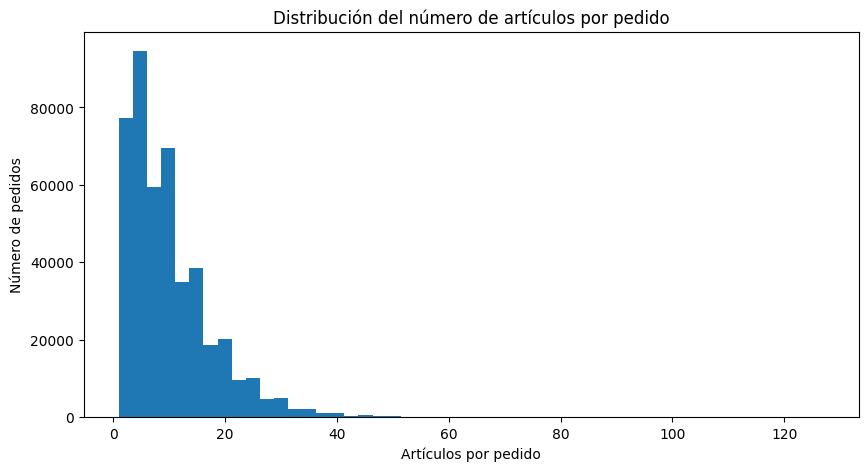

In [52]:
# Representamos la distribución de artículos por pedido.
items_per_order.plot(
    kind='hist',
    bins=50,
    figsize=(10, 5),
    title='Distribución del número de artículos por pedido',
    xlabel='Artículos por pedido'
)
plt.ylabel('Número de pedidos')
plt.show()


Normalmente las personas compran una cantidad relativamente pequeña de artículos: la **mediana es 8**, la **moda es 5** y el promedio es aproximadamente **10.1 artículos por pedido**. El histograma concentra la mayor parte de los pedidos a la izquierda y presenta una cola hacia la derecha. Hay pedidos más grandes, y el máximo observado es de **127 artículos**.


### [C2] ¿Cuáles son los 20 principales artículos que vuelven a pedirse con mayor frecuencia (muestra sus nombres e IDs de los productos)?

In [53]:
# Filtramos los productos que ya habían sido comprados anteriormente.
reordered_products = order_products[order_products['reordered'] == 1]
print('Productos marcados como recompra:', len(reordered_products))


Productos marcados como recompra: 2683838


In [54]:
# Contamos cuántas veces se recompró cada producto.
reordered_counts = reordered_products['product_id'].value_counts()
print(reordered_counts.head(20))


product_id
24852    55763
13176    44450
21137    28639
21903    26233
47209    23629
47766    18743
27845    16251
47626    15044
27966    14748
16797    13945
26209    13327
22935    11145
24964    10411
45007    10076
49683     9538
28204     8989
8277      8836
39275     8799
5876      8412
49235     8389
Name: count, dtype: int64


In [55]:
# Agregamos los nombres de los 20 productos más recomprados.
top20_reordered = (
    reordered_counts.head(20)
    .rename('reorder_count')
    .rename_axis('product_id')
    .reset_index()
    .merge(products[['product_id', 'product_name']], on='product_id', how='left')
)
top20_reordered = top20_reordered[['product_id', 'product_name', 'reorder_count']]


In [56]:
# Mostramos la lista de los artículos más recomprados.
print(top20_reordered.to_string(index=False))


 product_id             product_name  reorder_count
      24852                   Banana          55763
      13176   Bag of Organic Bananas          44450
      21137     Organic Strawberries          28639
      21903     Organic Baby Spinach          26233
      47209     Organic Hass Avocado          23629
      47766          Organic Avocado          18743
      27845       Organic Whole Milk          16251
      47626              Large Lemon          15044
      27966      Organic Raspberries          14748
      16797             Strawberries          13945
      26209                    Limes          13327
      22935     Organic Yellow Onion          11145
      24964           Organic Garlic          10411
      45007         Organic Zucchini          10076
      49683           Cucumber Kirby           9538
      28204       Organic Fuji Apple           8989
       8277 Apple Honeycrisp Organic           8836
      39275      Organic Blueberries           8799
       5876 

Los productos que más se vuelven a pedir son similares a los productos más populares. **Banana** (ID 24852) encabeza la lista con **55,763 recompras**, seguida de **Bag of Organic Bananas** (ID 13176), con **44,450**, y **Organic Strawberries** (ID 21137), con **28,639**. Esto sugiere compras repetidas de productos de consumo habitual.


### [C3] Para cada producto, ¿cuál es la proporción de las veces que se pide y que se vuelve a pedir?

In [57]:
# Contamos el total de pedidos en los que aparece cada producto.
product_total_orders = order_products.groupby('product_id')['order_id'].count()
print(product_total_orders.head())


product_id
1    280
2     11
3     42
4     49
7      2
Name: order_id, dtype: int64


In [58]:
# Sumamos los valores de reordered (1 significa recompra).
product_reordered_orders = order_products.groupby('product_id')['reordered'].sum()
print(product_reordered_orders.head())


product_id
1    158
2      0
3     31
4     25
7      1
Name: reordered, dtype: int64


In [59]:
# Dividimos las recompras entre el total y agregamos el nombre del producto.
product_reorder_rates = (
    (product_reordered_orders / product_total_orders)
    .rename('reorder_proportion')
    .rename_axis('product_id')
    .reset_index()
    .merge(products[['product_id', 'product_name']], on='product_id', how='left')
)
product_reorder_rates = product_reorder_rates[
    ['product_id', 'product_name', 'reorder_proportion']
]

# Mostramos la tabla completa como DataFrame; Colab puede abreviar la vista
# en pantalla, pero todos los productos quedan en product_reorder_rates.
print('Productos con pedidos registrados:', len(product_reorder_rates))
display(product_reorder_rates)
print()
print(product_reorder_rates['reorder_proportion'].describe())


Productos con pedidos registrados: 45573


,product_id,product_name,reorder_proportion
0,1,Chocolate Sandwich Cookies,0.564286
1,2,All-Seasons Salt,0.000000
2,3,Robust Golden Unsweetened Oolong Tea,0.738095
3,4,Smart Ones Classic Favorites Mini Rigatoni Wit...,0.510204
4,7,Pure Coconut Water With Orange,0.500000
...,...,...,...
45568,49690,HIGH PERFORMANCE ENERGY DRINK,0.800000
45569,49691,ORIGINAL PANCAKE & WAFFLE MIX,0.430556
45570,49692,ORGANIC INSTANT OATMEAL LIGHT MAPLE BROWN SUGAR,0.416667
45571,49693,SPRING WATER BODY WASH,0.440000



count    45573.000000
mean         0.386707
std          0.272132
min          0.000000
25%          0.166667
50%          0.408163
75%          0.575758
max          1.000000
Name: reorder_proportion, dtype: float64


Calculamos la proporción de recompra de cada producto dividiendo el número de veces que aparece con `reordered = 1` entre su total de apariciones. La proporción va de **0 a 1**: 0 significa que no observamos recompras y 1 que todas sus apariciones son recompras. Entre los productos pedidos, la mediana de esta proporción es aproximadamente **0.41**. Para productos sin ningún pedido registrado, no se puede calcular una proporción de recompra.


### [C4] Para cada cliente, ¿qué proporción de sus productos ya los había pedido?

In [60]:
# Combinamos los artículos pedidos con la tabla de pedidos para identificar al cliente.
order_products_users = order_products[['order_id', 'reordered']].merge(
    orders[['order_id', 'user_id']],
    on='order_id',
    how='inner'
)
print(order_products_users.head())


   order_id  reordered  user_id
0   2141543          0    58454
1    567889          1   129474
2   2261212          1    47476
3    491251          1   134505
4   2571142          1   155995


In [61]:
# La media de reordered (variable 0/1) es la proporción de artículos recomprados.
user_reorder_rates = (
    order_products_users.groupby('user_id')['reordered']
    .mean()
    .rename('reorder_proportion')
    .reset_index()
)
print(user_reorder_rates.head(20).to_string(index=False))
print()
print(user_reorder_rates['reorder_proportion'].describe())


 user_id  reorder_proportion
       2            0.038462
       4            0.000000
       5            0.666667
       6            0.000000
       7            0.928571
      11            0.200000
      12            0.250000
      13            0.565217
      14            0.360656
      15            0.538462
      16            0.531250
      17            0.716981
      19            0.291667
      20            0.000000
      21            0.400000
      22            1.000000
      24            0.500000
      26            0.437500
      27            0.658824
      28            0.500000

count    149626.000000
mean          0.494853
std           0.292685
min           0.000000
25%           0.272727
50%           0.500000
75%           0.724138
max           1.000000
Name: reorder_proportion, dtype: float64


Observamos que la proporción de productos recomprados varía entre clientes. La **mediana es 0.50** y la media es aproximadamente **0.495**. Esto significa que, para el cliente ubicado en la mitad de la distribución, cerca de la mitad de los artículos registrados corresponde a productos que ya había comprado antes.


### [C5] ¿Cuáles son los 20 principales artículos que las personas ponen primero en sus carritos?

In [62]:
# Filtramos los productos agregados en la primera posición del carrito.
first_cart_items = order_products[order_products['add_to_cart_order'] == 1]
print('Artículos añadidos en primera posición:', len(first_cart_items))


Artículos añadidos en primera posición: 450046


In [63]:
# Identificamos los 20 productos que más veces aparecen en primera posición.
first_counts = first_cart_items['product_id'].value_counts().head(20)
top20_first_items = (
    first_counts
    .rename('first_in_cart_count')
    .rename_axis('product_id')
    .reset_index()
    .merge(products[['product_id', 'product_name']], on='product_id', how='left')
)
top20_first_items = top20_first_items[
    ['product_id', 'product_name', 'first_in_cart_count']
]


In [64]:
# Mostramos el producto, su nombre y las veces que fue el primero en el carrito.
print(top20_first_items.to_string(index=False))


 product_id                product_name  first_in_cart_count
      24852                      Banana                15562
      13176      Bag of Organic Bananas                11026
      27845          Organic Whole Milk                 4363
      21137        Organic Strawberries                 3946
      47209        Organic Hass Avocado                 3390
      21903        Organic Baby Spinach                 3336
      47766             Organic Avocado                 3044
      19660                Spring Water                 2336
      16797                Strawberries                 2308
      27966         Organic Raspberries                 2024
      44632  Sparkling Water Grapefruit                 1914
      49235         Organic Half & Half                 1797
      47626                 Large Lemon                 1737
        196                        Soda                 1733
      38689    Organic Reduced Fat Milk                 1397
      26209             

**Banana** (ID 24852) es el producto que se añade primero al carrito con mayor frecuencia (**15,562 veces**), seguido de **Bag of Organic Bananas** (ID 13176), con **11,026 veces**. Varios artículos de la lista también destacan entre los más solicitados y los más recomprados, por lo que suelen ser productos habituales en las compras.


### Conclusion general del proyecto:

A partir del análisis observamos que los pedidos se realizan sobre todo durante el día, con una mayor actividad alrededor de las 10:00. El domingo es el día con más pedidos, y los miércoles y sábados presentan distribuciones horarias similares, aunque sus horas pico son diferentes.

El número de pedidos por cliente tiene una mediana de 9, mientras que los pedidos individuales contienen una mediana de 8 artículos. También encontramos que frutas y verduras, especialmente **Banana** y **Bag of Organic Bananas**, aparecen entre los productos más solicitados, más recomprados y añadidos primero al carrito.

En cuanto a la recompra, observamos una proporción mediana cercana a 0.41 para los productos pedidos y de 0.50 para los clientes. En general, los datos permiten identificar patrones de horarios de compra, tamaños de pedido y preferencias de productos de consumo frecuente.
